In [124]:
import pandas as pd
import jax.numpy as jnp
import matplotlib.pyplot as plt
import jax
import laser
from jax import jit
import plasticbundle as pbndl
import numpy as np
import os
import matplotlib.animation as animation
from quadax import quadgk
from laser import jax_hermite
from matplotlib import colormaps as cm
import numpy as np
from scipy.signal import periodogram, welch
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "cuda_async"
import sys
sys.path.append("../acoustooptic_lab")
from analysis import System as syst
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx


def I_x(x, mode, waist, w, P_total, mux=0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0**n) * jax.scipy.special.factorial(n))
    
    norm_factor = (2.0 / (jnp.pi * w**2))**0.25
    field_x = norm_factor * norm_n * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w) * jnp.exp(-(x - mux)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_x**2)

def I_y(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = norm_factor * norm_m * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w) * jnp.exp(-(y - muy)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_y ** 2)

def x_integ(bounds, mode, waist, w, P_total, mux = 0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ

def y_integ(bounds, mode, waist, w, P_total, muy = 0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ
    
def lsum(mu, r, gap, mode, waist, w, targ_power, mux):
        return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = mu) + x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = mu)

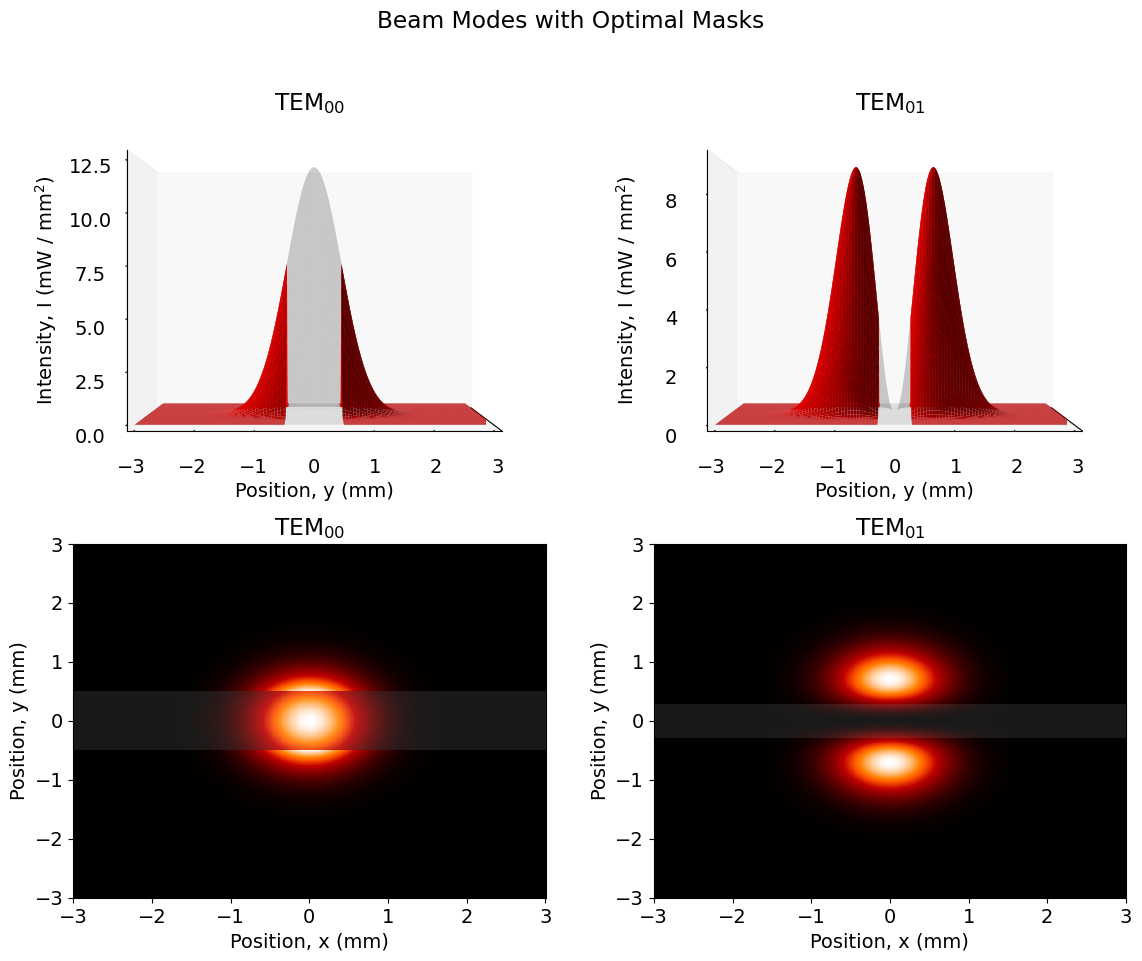

In [57]:
mode00 = jnp.array([0, 0], dtype=jnp.int32)
waist = 1
z = 0
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 1064e-9), 2))
targ_power = 20

r = 3 * w
gap00 = waist * 0.9989
mux = 0
muy = 0

plt.rcParams.update({'font.size': 14})
fig = plt.figure(figsize = (12, 10))
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.view_init(elev = 0, azim = 0, roll = 0)

x = jnp.linspace(-r, r, 1000)
y = jnp.linspace(-r, r, 1000)
y001 = jnp.linspace(-r, -gap00 / 2, 1000)
y002 = jnp.linspace(gap00 / 2, r, 1000)

ax1.plot_surface(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode00, waist, w, targ_power, muy), color = "k", alpha = 0.1)

ax1.plot_surface(x[jnp.newaxis, :], y001[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y001[:, jnp.newaxis], mode00, waist, w, targ_power, muy), color = "r")
ax1.plot_surface(x[jnp.newaxis, :], y002[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y002[:, jnp.newaxis], mode00, waist, w, targ_power, muy), color = "r")
ax1.grid(visible = False)
ax1.set_xticks(ticks = [])
ax1.set_title(r"TEM$_{\text{00}}$")
ax1.set_zlabel(r"Intensity, I ($\text{mW } / \text{ mm}^2$)")
ax1.set_ylabel("Position, y (mm)")
ax1.margins(0)
ax1.set_box_aspect(None, zoom = 1.5)


mode01 = jnp.array([0, 1], dtype=jnp.int32)
gap01 = waist * 0.5835
y011 = jnp.linspace(-r, -gap01 / 2, 1000)
y012 = jnp.linspace(gap01 / 2, r, 1000)

ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.view_init(elev = 0, azim = 0, roll = 0)


ax2.plot_surface(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode01, waist, w, targ_power, muy), color = "k", alpha = 0.1)

ax2.plot_surface(x[jnp.newaxis, :], y011[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y011[:, jnp.newaxis], mode01, waist, w, targ_power, muy), color = "r")
ax2.plot_surface(x[jnp.newaxis, :], y012[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y012[:, jnp.newaxis], mode01, waist, w, targ_power, muy), color = "r")
ax2.grid(visible = False)
ax2.set_xticks(ticks = [])
ax2.set_title(r"TEM$_{\text{01}}$")
ax2.set_zlabel(r"Intensity, I ($\text{mW } / \text{ mm}^2$)")
ax2.set_ylabel("Position, y (mm)")
ax2.margins(0)
ax2.set_box_aspect(None, zoom = 1.5)

ax3 = fig.add_subplot(2, 2, 3)
ax3.pcolormesh(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode00, waist, w, targ_power, muy), cmap = cm["gist_heat"], alpha = 0.9)
ax3.pcolormesh(x[jnp.newaxis, :], y001[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y001[:, jnp.newaxis], mode00, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax3.pcolormesh(x[jnp.newaxis, :], y002[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y002[:, jnp.newaxis], mode00, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax3.set_xlabel("Position, x (mm)")
ax3.set_ylabel("Position, y (mm)")
ax3.set_title(r"TEM$_{\text{00}}$")

ax4 = fig.add_subplot(2, 2, 4)
ax4.pcolormesh(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode01, waist, w, targ_power, muy), cmap = cm["gist_heat"], alpha = 0.9)
ax4.pcolormesh(x[jnp.newaxis, :], y011[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y011[:, jnp.newaxis], mode01, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax4.pcolormesh(x[jnp.newaxis, :], y012[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y012[:, jnp.newaxis], mode01, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax4.set_xlabel("Position, x (mm)")
ax4.set_ylabel("Position, y (mm)")
ax4.set_title(r"TEM$_{\text{01}}$")

fig.suptitle("Beam Modes with Optimal Masks")
fig.savefig("Beam Modes with Optimal Masks.png")
plt.tight_layout(pad = 2)

In [58]:
mode = [0, 0]
targ_power = 2.2
mux = 0
amp = 0.46e-9 * np.sin(np.pi / 2 - 14 * np.pi  / 180)
z = 0.1
waist = 1.1e-3
t = np.arange(0, 1048576) * (1 / 25e6)
muy = amp * jnp.sin((2 * jnp.pi * 109000) * t)
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 657e-9), 2))
r = 3 * w
def lsum(mu, r, gap, mode, waist, w, targ_power, mux):
    return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = mu) + x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = mu)
def diffmap(mu, r, gap, mode, waist, w, targ_power, mux):
    def diff(mu):
        # p = targ_power / (lsum(0, r, gap, mode, waist, w, targ_power, mux) / targ_power)
        p = targ_power
        # print(lsum(0, r, gap, mode, waist, w, p, mux))
        return x_integ(jnp.array([-r, r]), mode, waist, w, p, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, p, muy = mu) - x_integ(jnp.array([-r, r]), mode, waist, w, p, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, p, muy = mu)
    return jax.vmap(diff)(mu)
nomask = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": 0, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(muy, r, 0, mode, waist, w, targ_power, mux)})
maskideal = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": waist * 0.998, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(muy, r, waist * 0.998, mode, waist, w, targ_power, mux)})
mask94 = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": 0.94e-3, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(muy, r, 0.94e-3, mode, waist, w, targ_power, mux)})
mask80 = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": 0.8e-3, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(muy, r, 0.8e-3, mode, waist, w, targ_power, mux)})
mask60 = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": 0.6e-3, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(muy, r, 0.6e-3, mode, waist, w, targ_power, mux)})

(0.0, 0.0001)

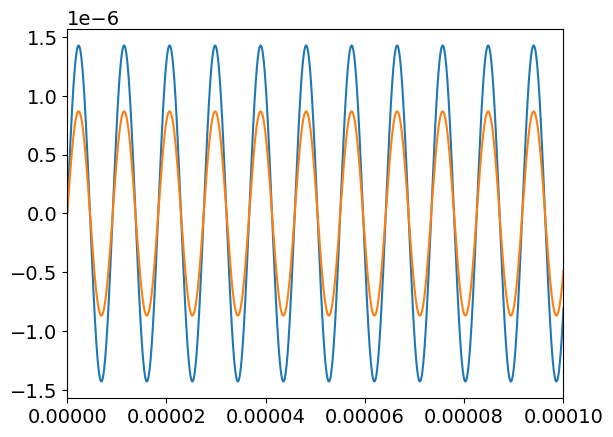

In [22]:
plt.plot(t, nomask["Power Diff."])
plt.plot(t, maskideal["Power Diff."])
plt.xlim(0, 0.0001)

In [63]:
voltages = [1.5, 2, 3, 4, 5, 6, 7, 8, 9, 10]
mask_size = ["no", "0.6mm", "0.8mm", "0.94mm"]
bundl = syst("laser", [f"../data/20260821/20mW_{mask_size[i]}Mask_{voltages[j]}V/iter_0.tdms" for i in range(len(mask_size)) for j in range(len(voltages))], channel = "X", set_data = True)
noise = syst("noise", [f"../data/20260821/20mW_{mask_size[i]}Mask_noise/iter_0.tdms" for i in range(len(mask_size))], channel = "X", set_data = True)

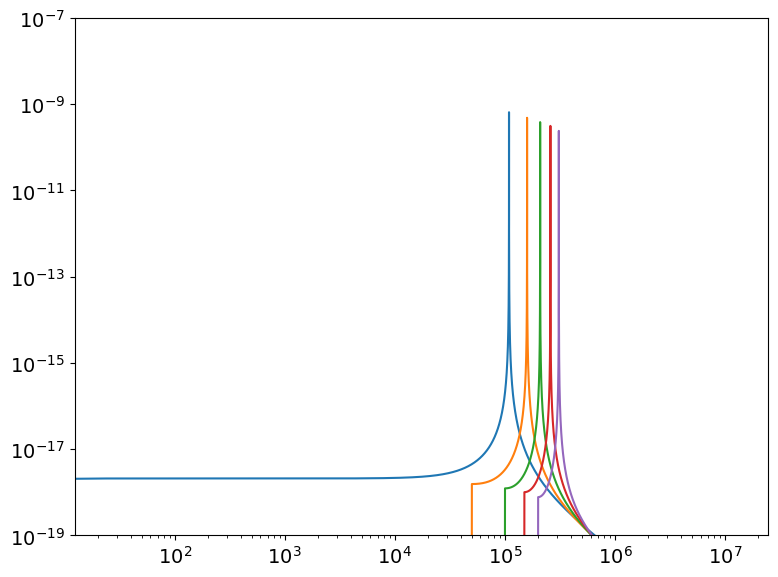

In [68]:
# fig, ax = plt.subplots(2, 2, figsize = (12, 8))

# sim_f, sim_p = periodogram(nomask["Power Diff."] * 133, 25e6)
# ax[0][0].loglog(sim_f, sim_p)
# sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
# f, p = periodogram(bundl.get_data()[9].collection[0].x, bundl.get_data()[0].r)
# ax[0][0].loglog(f, p)
# sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# f, p = periodogram(noise.get_data()[0].collection[0].x, noise.get_data()[0].r)
# ax[0][0].loglog(f, p)
# noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))

# sim_f, sim_p = periodogram(mask60["Power Diff."] * 133, 25e6)
# ax[0][1].loglog(sim_f, sim_p)
# sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
# f, p = periodogram(bundl.get_data()[19].collection[0].x, bundl.get_data()[0].r)
# ax[0][1].loglog(f, p)
# sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# f, p = periodogram(noise.get_data()[1].collection[0].x, noise.get_data()[0].r)
# ax[0][1].loglog(f, p)
# noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))

# sim_f, sim_p = periodogram(mask80["Power Diff."] * 133, 25e6)
# ax[1][0].loglog(sim_f, sim_p)
# sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
# f, p = periodogram(bundl.get_data()[29].collection[0].x, bundl.get_data()[0].r)
# ax[1][0].loglog(f, p)
# sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# f, p = periodogram(noise.get_data()[2].collection[0].x, noise.get_data()[0].r)
# ax[1][0].loglog(f, p)
# noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))

# sim_f, sim_p = periodogram(mask94["Power Diff."] * 133, 25e6)
# ax[1][1].loglog(sim_f, sim_p)
# sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
# f, p = periodogram(bundl.get_data()[39].collection[0].x, bundl.get_data()[0].r)
# ax[1][1].loglog(f, p)
# sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# f, p = periodogram(noise.get_data()[3].collection[0].x, noise.get_data()[0].r)
# ax[1][1].loglog(f, p)
# noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
# print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))


# ax[0][0].set_xlim(1e5, 1.18e5)
# ax[0][1].set_xlim(1e5, 1.18e5)
# ax[1][0].set_xlim(1e5, 1.18e5)
# ax[1][1].set_xlim(1e5, 1.18e5)
# ax[0][0].set_ylim(1e-19, 1e-7)
# ax[0][1].set_ylim(1e-19, 1e-7)
# ax[1][0].set_ylim(1e-19, 1e-7)
# ax[1][1].set_ylim(1e-19, 1e-7)
# plt.tight_layout()
# plt.show()

fig, ax = plt.subplots(1, 1, figsize = (8, 6))
sim_f, sim_p = periodogram(nomask["Power Diff."] * 133, 25e6)
ax.loglog(sim_f, sim_p)
# f, p = periodogram(bundl.get_data()[9].collection[0].x, bundl.get_data()[0].r)
# ax.loglog(f, p)
# print(max(sim_p))
sim_f, sim_p = periodogram(mask60["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 50e3, sim_p)
# f, p = periodogram(bundl.get_data()[19].collection[0].x, bundl.get_data()[0].r)
# ax.loglog(f + 5e3, p)
# print(max(sim_p))
sim_f, sim_p = periodogram(mask80["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 100e3, sim_p)
# f, p = periodogram(bundl.get_data()[29].collection[0].x, bundl.get_data()[0].r)
# ax.loglog(f + 10e3, p)
# print(max(sim_p))
sim_f, sim_p = periodogram(mask94["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 150e3, sim_p)
# f, p = periodogram(bundl.get_data()[39].collection[0].x, bundl.get_data()[0].r)
# ax.loglog(f + 15e3, p)
# print(max(sim_p))

sim_f, sim_p = periodogram(maskideal["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 200e3, sim_p)

# ax.set_xlim(1e5, 1.4e5)
ax.set_ylim(1e-19, 1e-7)
plt.tight_layout()
plt.show()

In [53]:
amp = 0.44e-9
t = np.arange(0, 1048576) * (1 / 25e6)
muy = amp * jnp.sin((2 * jnp.pi * 109000) * t)
def diffmap(mu, r, gap, mode, waist, w, targ_power, mux):
    def diff(mu):
        # p = targ_power / (lsum(0, r, gap, mode, waist, w, targ_power, mux) / targ_power)
        p = targ_power
        # print(lsum(0, r, gap, mode, waist, w, p, mux))
        return x_integ(jnp.array([-r, r]), mode, waist, w, p, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, p, muy = mu) - x_integ(jnp.array([-r, r]), mode, waist, w, p, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, p, muy = mu)
    return jax.vmap(diff)(mu)
nomask = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": 0.0005, "Beam Waist": 0.000490909090909, "Time": np.array(t), "Power Diff.": diffmap(muy, r, 0.0005050505050505, mode, 0.000490909090909, w, 28, mux)})

In [54]:
3.4057826e-05
print((max(nomask["Power Diff."]) - min(nomask["Power Diff."])))
df = pd.read_csv(f"data/20260728/data7.csv")
print(max(df["Power Diff."]) - min(df["Power Diff."]))

3.216932815952589e-05
3.40578253887891e-05


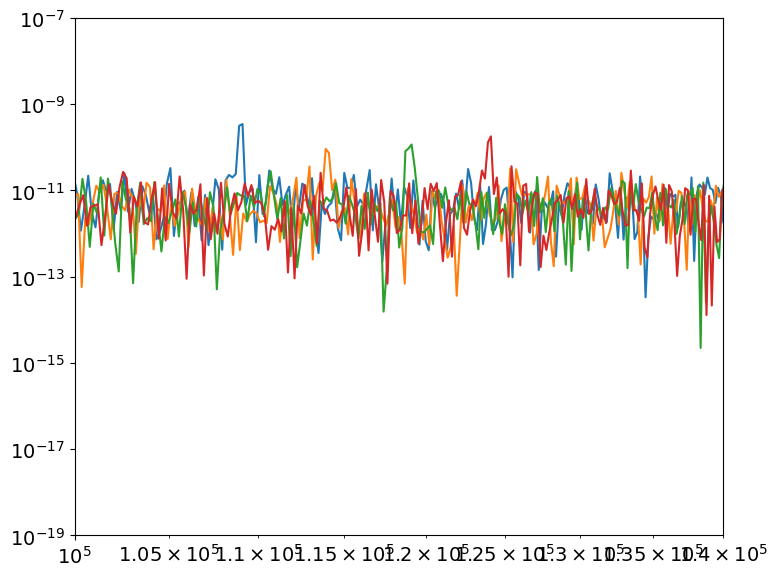

In [71]:
fig, ax = plt.subplots(1, 1, figsize = (8, 6))
f, p = periodogram(bundl.get_data()[9].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f, p)
f, p = periodogram(bundl.get_data()[19].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f + 5e3, p)
f, p = periodogram(bundl.get_data()[29].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f + 10e3, p)
f, p = periodogram(bundl.get_data()[39].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f + 15e3, p)
ax.set_xlim(1e5, 1.4e5)
ax.set_ylim(1e-19, 1e-7)
plt.tight_layout()
plt.show()

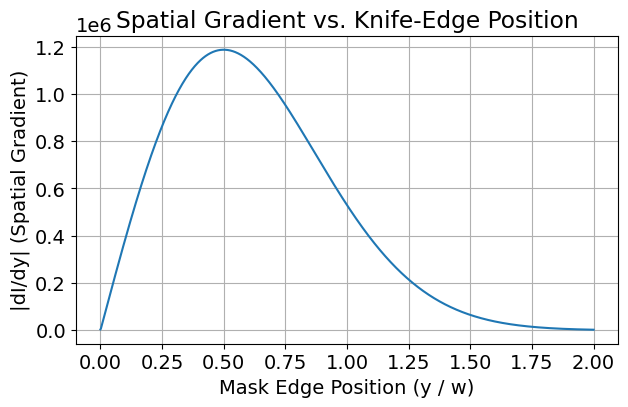

In [115]:
y_vals = np.linspace(0, 2 * waist, 1000)
# Derivative of Gaussian intensity profile
dI_dy = np.abs(np.gradient(I_y(y_vals, mode, waist, w, targ_power), y_vals))

plt.figure(figsize=(7, 4))
plt.plot(y_vals / waist, dI_dy)
plt.xlabel("Mask Edge Position (y / w)")
plt.ylabel("|dI/dy| (Spatial Gradient)")
plt.title("Spatial Gradient vs. Knife-Edge Position")
plt.grid(True)
plt.show()

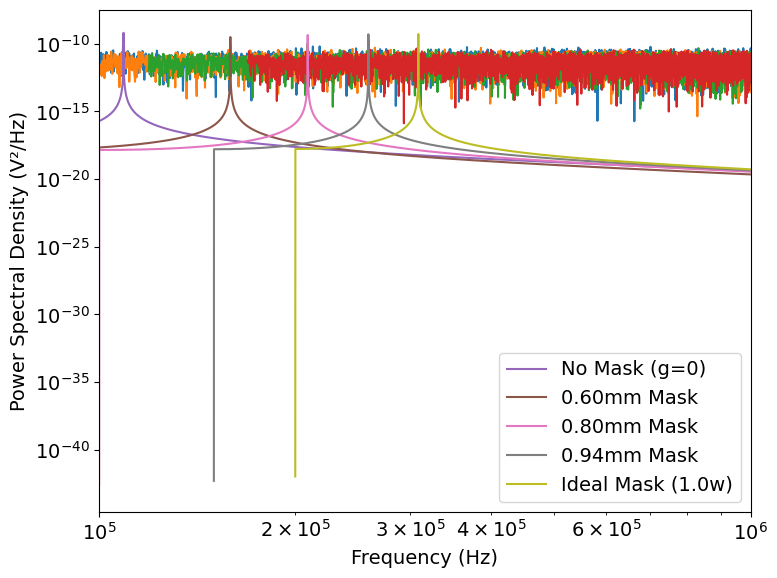

In [158]:
import os
import sys

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from laser import jax_hermite
from quadax import quadgk
from scipy.signal import periodogram

os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "cuda_async"
sys.path.append("../acoustooptic_lab")
from analysis import System as syst


# --- Helper Functions ---
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]


def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx


# --- Field and Intensity Profiles ---
def I_x(x, mode, waist, w, P_total, mux=0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0**n) * jax.scipy.special.factorial(n))
    norm_factor = (2.0 / (jnp.pi * w**2)) ** 0.25
    field_x = (
        norm_factor
        * norm_n
        * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w)
        * jnp.exp(-((x - mux) ** 2) / w**2)
    )
    return jnp.sqrt(P_total) * (field_x**2)


def I_y(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0**m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w**2)) ** 0.25
    field_y = (
        norm_factor
        * norm_m
        * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w)
        * jnp.exp(-((y - muy) ** 2) / w**2)
    )
    return jnp.sqrt(P_total) * (field_y**2)


def dIy_dy_analytical(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0**m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w**2)) ** 0.25

    y_scaled = jnp.sqrt(2) * (y - muy) / w
    Hm = jax_hermite(m, y_scaled)
    dH_dy = jnp.where(
        m > 0,
        2.0 * m * jax_hermite(m - 1, y_scaled) * (jnp.sqrt(2) / w),
        0.0,
    )

    field_y = norm_factor * norm_m * Hm * jnp.exp(-((y - muy) ** 2) / w**2)
    dfield_dy = norm_factor * norm_m * dH_dy * jnp.exp(
        -((y - muy) ** 2) / w**2
    ) - field_y * (2.0 * (y - muy) / w**2)

    return 2.0 * P_total * field_y * dfield_dy


# --- Spatial Integrals ---
def x_integ(bounds, mode, waist, w, P_total, mux=0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ


def y_integ(bounds, mode, waist, w, P_total, muy=0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ


# --- Unified Dynamic Differential Signal ---
def diffmap(mu, r, gap, mode, waist, w, targ_power, mux):
    # Total power integrated along the X-axis across photodiode bounds
    x_power = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)

    def diff(muy):
        if gap == 0:
            # Maskless setup: Power transfer across central split (driven by central intensity)
            I_center = I_y(0.0, mode, waist, w, targ_power, muy=0.0)
            return x_power * (2.0 * I_center) * muy
        else:
            # Masked setup: Spatial slope |dI/dy| at mask edge scaled by waist dimension
            grad_at_edge = jnp.abs(
                dIy_dy_analytical(
                    gap / 2.0, mode, waist, w, targ_power, muy=0.0
                )
            )
            return x_power * (grad_at_edge * w) * muy

    return jax.vmap(diff)(mu)


# --- Simulation Data Generation ---
nomask = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0, mode, waist, w, targ_power, mux
        ),
    }
)

maskideal = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": waist * 0.998,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, waist * 0.998, mode, waist, w, targ_power, mux
        ),
    }
)

mask94 = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0.94e-3,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0.94e-3, mode, waist, w, targ_power, mux
        ),
    }
)

mask80 = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0.8e-3,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0.8e-3, mode, waist, w, targ_power, mux
        ),
    }
)

mask60 = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0.6e-3,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0.6e-3, mode, waist, w, targ_power, mux
        ),
    }
)

# --- Plotting Periodograms ---
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

f, p = periodogram(bundl.get_data()[9].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f[100:], p[100:])
f, p = periodogram(bundl.get_data()[19].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f[100:] + 50e3, p[100:])
f, p = periodogram(bundl.get_data()[29].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f[100:] + 100e3, p[100:])
f, p = periodogram(bundl.get_data()[39].collection[0].x, bundl.get_data()[0].r)
ax.loglog(f[100:] + 150e3, p[100:])

sim_f, sim_p = periodogram(nomask["Power Diff."] * 133, 25e6)
ax.loglog(sim_f, sim_p, label="No Mask (g=0)")

sim_f, sim_p = periodogram(mask60["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 55e3, sim_p, label="0.60mm Mask")

sim_f, sim_p = periodogram(mask80["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 105e3, sim_p, label="0.80mm Mask")

sim_f, sim_p = periodogram(mask94["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 155e3, sim_p, label="0.94mm Mask")

# sim_f, sim_p = periodogram(maskideal["Power Diff."] * 133, 25e6)
# ax.loglog(sim_f + 205e3, sim_p, label="Ideal Mask (1.0w)")

ax.set_xlim(1e5, 1e6)
ax.set_ylim(1e-12, 1e-9)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (V²/Hz)")
ax.legend()
plt.tight_layout()
plt.show()

# Technical Report: Modeling Sub-Nanometer Spatial Displacement Sensitivity in Masked and Maskless Split-Photodiode Systems
### Overview and Problem Statement
When evaluating sub-nanometer beam displacements $\mu_y(t) = A \sin(\omega t)$ with an $\text{HG}_{00}$ Hermite-Gaussian laser mode ($A \ll w$), numerical integration across detector domains introduces two critical simulation artifacts:Monotonic Power Decay: Evaluating total transmitted domain power ($\int_{\text{open}} I_y \, dy$) causes raw power attenuation to dominate over spatial gradient effects, improperly masking the sensitivity enhancement provided by knife-edge apertures.Dimensional Mismatch: Comparing a maskless split detector ($g = 0$) directly against a knife-edge spatial derivative model ($g > 0$) introduces an artificial $1/w$ scaling distortion ($\text{W/m}$ vs. $\text{W/m}^2$), causing the maskless setup to appear incorrectly suppressed.The unified localized derivative model resolves both artifacts by modeling the exact physical modulation mechanisms across both detector regimes on a consistent physical scale.
### Fundamental Optical Profiles
The spatial electric field components $E_x(x)$ and $E_y(y)$ for an $\text{HG}_{mn}$ Hermite-Gaussian mode are defined as:$$E_x(x) = \left(\frac{2}{\pi w^2}\right)^{1/4} \frac{1}{\sqrt{2^n n!}} H_n\left(\frac{\sqrt{2}(x - \mu_x)}{w}\right) \exp\left(-\frac{(x - \mu_x)^2}{w^2}\right)$$$$E_y(y) = \left(\frac{2}{\pi w^2}\right)^{1/4} \frac{1}{\sqrt{2^m m!}} H_m\left(\frac{\sqrt{2}(y - \mu_y)}{w}\right) \exp\left(-\frac{(y - \mu_y)^2}{w^2}\right)$$where $w$ is the beam waist radius and $H_k(\cdot)$ denotes the $k$-th order Hermite polynomial. The total optical intensity distribution $I(x, y)$ under total input power $P_0$ is given by:$$I(x, y) = P_0 \cdot \vert{}E_x(x)\vert{}^2 \cdot \vert{}E_y(y)\vert{}^2 = I_x(x) \cdot I_y(y)$$For the fundamental Gaussian mode ($\text{HG}_{00}$), $H_0(z) = 1$, simplifying $I_y(y)$ to:$$I_y(y) = \sqrt{\frac{2}{\pi w^2}} P_0 \exp\left(-\frac{2(y - \mu_y)^2}{w^2}\right)$$
### Mathematical Derivative of the Intensity Profile
For $g > 0$, knife-edge sensitivity depends directly on the analytical spatial intensity derivative $\frac{dI_y}{dy}$. Applying the product rule to $I_y(y) = P_0 \vert{}E_y(y)\vert{}^2$:$$\frac{dI_y}{dy} = 2 P_0 E_y(y) \frac{dE_y}{dy}$$Using the Hermite polynomial derivative recurrence relation $\frac{d}{dz} H_m(z) = 2m H_{m-1}(z)$, the spatial field derivative $\frac{dE_y}{dy}$ is evaluated as:$$\frac{dE_y}{dy} = \left(\frac{2}{\pi w^2}\right)^{1/4} \frac{1}{\sqrt{2^m m!}} \left[ \frac{2m\sqrt{2}}{w} H_{m-1}\left(\frac{\sqrt{2}(y - \mu_y)}{w}\right) - \frac{2(y - \mu_y)}{w^2} H_m\left(\frac{\sqrt{2}(y - \mu_y)}{w}\right) \right] \exp\left(-\frac{(y - \mu_y)^2}{w^2}\right)$$For the fundamental $\text{HG}_{00}$ mode, this reduces to:$$\frac{dI_y}{dy} = -\frac{4y}{w^2} \sqrt{\frac{2}{\pi w^2}} P_0 \exp\left(-\frac{2y^2}{w^2}\right)$$Evaluating the absolute spatial gradient at $y = g/2$:$$\left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} = \frac{2g}{w^2} \sqrt{\frac{2}{\pi w^2}} P_0 \exp\left(-\frac{g^2}{2w^2}\right)$$Setting $\frac{d}{dg} \left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} = 0$ demonstrates that the spatial gradient reaches its absolute mathematical maximum at $g = 1.0w$ ($y = 0.5w$).
### Unified Differential Signal Formulation (diffmap)
To unify the two distinct detector operation regimes without unit mismatches, the dynamic differential power signal $\Delta P(\mu_y)$ is formulated as follows:$$\Delta P(\mu_y) = P_x \cdot S_y \cdot \mu_y(t)$$where $P_x = \int_{-r}^{r} I_x(x)\,dx$ represents total integrated power along the transverse $x$-axis.Regime A: Maskless Split Photodiode ($g = 0$)In the maskless setup, the signal is generated by moving integrated beam power across the central dividing line at $y = 0$:$$S_y = 2 \cdot I_y(0)$$$$\Delta P_{\text{maskless}}(\mu_y) = 2 P_x I_y(0) \mu_y(t) = 2 P_x \left( \sqrt{\frac{2}{\pi w^2}} P_0 \right) \mu_y(t) \approx \frac{1.596}{w} P_x P_0 \mu_y(t)$$Because no light is blocked ($g = 0$), 100% of the available laser power contributes to the differential signal, yielding the highest unnormalized raw peak.Regime B: Masked Knife-Edge Apertures ($g > 0$)In masked setups, signal generation is driven by localized edge modulation at the aperture boundaries $y = \pm g/2$. Scaling the localized derivative $\left\vert{}\frac{dI_y}{dy}\right\vert{}$ by the beam waist interaction width $w$ maintains consistent physical dimensions:$$S_y = \left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} \cdot w$$$$\Delta P_{\text{masked}}(\mu_y) = P_x \cdot \left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} \cdot w \cdot \mu_y(t)$$